# 06. 유저 군집 — 리뷰 시점 특성 4개로 페르소나 3개

**입력**: `dataSets/starfield_analysis.csv`, `dataSets/reviews_for_embedding.csv` (분석 대상 id), `dataSets/추천확률.csv`
**출력**: `dataSets/유저군집.csv`, `out/06_*.png`

군집 변수는 **리뷰를 쓰는 순간에 알 수 있는 값** 4개만 쓴다: 보유 게임 수 · 작성 리뷰 수 · 리뷰 시점 플레이시간 · 리뷰 시점 업적 수.
"리뷰 후 플레이시간"은 결과이지 원인이 아니므로 군집 변수에 넣지 않는다.

순서: 상한값 대체 → 로그 → 표준화 → K-Means(k=3) → 이름 붙이기 → 프로파일 표

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, roc_auc_score

RANDOM_STATE = 3217
os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)                                   # 폰트 파일 등록
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()   # 파일 안의 폰트 이름을 읽어 지정
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

PERSONAS = ['하드 리뷰어', '초기 리뷰어', '라이트 리뷰어']
COLOR = {'하드 리뷰어': '#4C72B0', '초기 리뷰어': '#DD8452', '라이트 리뷰어': '#55A868'}

## 1. 데이터 로드

In [2]:
meta = pd.read_csv('dataSets/starfield_analysis.csv', low_memory=False)
pop = pd.read_csv('dataSets/reviews_for_embedding.csv', usecols=['steamid'])
df = meta.merge(pop, on='steamid', how='inner').reset_index(drop=True)
print('분석 대상', len(df), '행')

df['len'] = df['review'].str.len()
df['days_since_release'] = (df['ts_created'] - df['app_release_date']) / 86400   # 출시 후 며칠째 쓴 리뷰인지

분석 대상 70915 행


## 2. 전처리

1. **상한값 대체**: 보유 게임·리뷰 수·플레이시간(리뷰 시점·총)의 상위 0.5%를 그 지점 값으로 바꾼다 (04와 같은 처리).
   업적 수는 최대 82가 "완주"라는 진짜 신호라 바꾸지 않는다.
2. **로그**: 네 변수 모두 오른쪽 꼬리가 길다. 최솟값이 1 이상인 세 변수는 log, 0이 있는 업적 수는 log1p.
3. **표준화**: 변수마다 단위가 다르므로 평균 0, 표준편차 1로 맞춘다.

In [3]:
FEATURES = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review']
WINSORIZE = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'playtime_forever_min']

for col in WINSORIZE:
    cap = df[col].quantile(0.995)
    n_over = (df[col] > cap).sum()
    df[col] = df[col].clip(upper=cap)
    print(col, '상한', round(cap), '/ 대체', n_over, '건')

X = df[FEATURES].astype(float).copy()
X['games_owned'] = np.log(X['games_owned'])
X['num_reviews'] = np.log(X['num_reviews'])
X['playtime_at_review_min'] = np.log(X['playtime_at_review_min'])
X['n_ach_at_review'] = np.log1p(X['n_ach_at_review'])

scaler = StandardScaler()
Z = scaler.fit_transform(X)     # 표준화된 값 (numpy 배열)

print()
print('로그 후 상관')
print(X.corr().round(2))

games_owned 상한 3467 / 대체 355 건
num_reviews 상한 281 / 대체 355 건
playtime_at_review_min 상한 38822 / 대체 355 건
playtime_forever_min 상한 85910 / 대체 355 건

로그 후 상관
                        games_owned  num_reviews  playtime_at_review_min  \
games_owned                    1.00         0.52                    0.03   
num_reviews                    0.52         1.00                   -0.06   
playtime_at_review_min         0.03        -0.06                    1.00   
n_ach_at_review                0.05        -0.05                    0.76   

                        n_ach_at_review  
games_owned                        0.05  
num_reviews                       -0.05  
playtime_at_review_min             0.76  
n_ach_at_review                    1.00  


## 3. 군집 수(k) 정하기

k를 2~8로 바꿔 가며 이너셔(엘보우)와 실루엣을 본다. 실루엣은 계산이 무거워 8,000명 표본으로 계산한다.
k가 작을 때는 군집 중심도 같이 출력해, 어떤 변수로 갈리는지 본다.

k=2 군집 중심 (표준화 값)
   games_owned  num_reviews  playtime_at_review_min  n_ach_at_review
0        -0.07         0.06                   -0.88            -0.96
1         0.05        -0.04                    0.61             0.66

k=3 군집 중심 (표준화 값)
   games_owned  num_reviews  playtime_at_review_min  n_ach_at_review
0         0.71         0.68                    0.47             0.49
1        -0.06         0.10                   -1.14            -1.14
2        -0.72        -0.83                    0.47             0.46

k=4 군집 중심 (표준화 값)
   games_owned  num_reviews  playtime_at_review_min  n_ach_at_review
0         0.72         0.70                    0.48             0.49
1        -0.54        -0.70                    0.73             0.83
2         0.47         0.67                   -1.21            -1.18
3        -0.82        -0.76                   -0.59            -0.75

   k     inertia  silhouette
0  2  199821.844       0.279
1  3  152464.982       0.261
2  4  131708.808       0.233

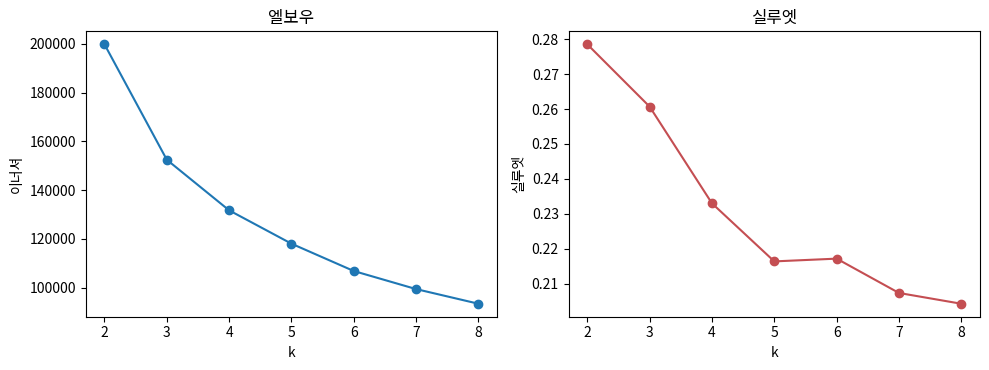

In [4]:
rng = np.random.RandomState(RANDOM_STATE)
sample = rng.choice(len(Z), 8000, replace=False)

ks = []
inertias = []
silhouettes = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Z)
    ks.append(k)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z[sample], km.labels_[sample]))
    if k <= 4:
        print(f'k={k} 군집 중심 (표준화 값)')
        print(pd.DataFrame(km.cluster_centers_, columns=FEATURES).round(2))
        print()

scores = pd.DataFrame({'k': ks, 'inertia': inertias, 'silhouette': silhouettes})
print(scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(ks, inertias, marker='o')
axes[0].set_xlabel('k')
axes[0].set_ylabel('이너셔')
axes[0].set_title('엘보우')
axes[1].plot(ks, silhouettes, marker='o', color='#C44E52')
axes[1].set_xlabel('k')
axes[1].set_ylabel('실루엣')
axes[1].set_title('실루엣')
fig.tight_layout()
fig.savefig('out/06_군집_k탐색.png', dpi=120)
plt.show()

실루엣은 k=2(0.28)가 가장 높지만, k=2는 플레이시간·업적 축으로만 갈리는 "플레이 많음/적음" 이분법이다.
k=3에서 처음으로 보유 게임·리뷰 수 축이 갈라지고, k=4는 실루엣이 0.23으로 떨어진다. 두 축이 모두 드러나는 가장 작은 **k=3**을 쓴다.

실루엣 0.26은 경계가 뚜렷한 군집이 아니다. 행동 데이터는 연속 분포라 이 정도가 보통이고, 여기서는 "세그먼트 도구"로 쓴다.
대신 시드를 바꿔도 배정이 같은지(ARI) 확인한다.

In [5]:
K = 3
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(Z)
df['cluster'] = km.labels_

# 시드를 바꿔 다시 군집화해도 같은 배정이 나오는지 (ARI 1 = 완전히 같음, 0.9 이상이면 안정)
aris = []
for seed in range(1, 6):
    other = KMeans(n_clusters=K, random_state=seed, n_init=10).fit_predict(Z)
    aris.append(round(adjusted_rand_score(km.labels_, other), 3))
print('시드 변경 시 배정 일치도(ARI):', aris)

시드 변경 시 배정 일치도(ARI): [1.0, 1.0, 0.974, 0.988, 0.994]


## 4. 군집에 이름 붙이기와 프로파일

군집 번호(0, 1, 2)는 실행 환경에 따라 바뀔 수 있어서 번호에 이름을 직접 붙이지 않고,
각 군집의 중심값을 보고 규칙으로 정한다:
- 리뷰 시점 플레이시간이 가장 적은 군집 → **초기 리뷰어**
- 리뷰 수가 가장 많은 군집 → **하드 리뷰어**
- 보유 게임이 가장 적은 군집 → **라이트 리뷰어**

In [6]:
centers = pd.DataFrame(km.cluster_centers_, columns=FEATURES)
print('군집 중심 (표준화 값)')
print(centers.round(2))

id_early = centers['playtime_at_review_min'].idxmin()
id_hard = centers['num_reviews'].idxmax()
id_light = centers['games_owned'].idxmin()
if len({id_early, id_hard, id_light}) != 3:
    raise ValueError('규칙이 같은 군집을 가리킨다 — 중심표를 보고 규칙을 다시 정할 것')

cluster_to_name = {id_hard: '하드 리뷰어', id_early: '초기 리뷰어', id_light: '라이트 리뷰어'}
df['페르소나'] = df['cluster'].map(cluster_to_name)

# 07·08이 읽는 군집 이름도 같이 저장해 둔다
old_name = {'하드 리뷰어': '하드코어 리뷰어', '초기 리뷰어': '초반 리뷰어', '라이트 리뷰어': '라이트 몰입형'}
df['군집'] = df['페르소나'].map(old_name)

df[['steamid', 'cluster', '군집', '페르소나']].to_csv('dataSets/유저군집.csv', index=False)
print('저장: dataSets/유저군집.csv')

군집 중심 (표준화 값)
   games_owned  num_reviews  playtime_at_review_min  n_ach_at_review
0         0.71         0.68                    0.47             0.49
1        -0.06         0.10                   -1.14            -1.14
2        -0.72        -0.83                    0.47             0.46
저장: dataSets/유저군집.csv


In [7]:
# 프로파일: 각 군집의 원래 값 중앙값 (정규분포가 아니라 평균 대신 중앙값)
profile = df.groupby('페르소나').agg(
    n=('steamid', 'size'),
    보유게임=('games_owned', 'median'),
    리뷰수=('num_reviews', 'median'),
    리뷰시점_플레이분=('playtime_at_review_min', 'median'),
    업적=('n_ach_at_review', 'median'),
    단계=('stage_at_review', 'median'),
    출시후_일=('days_since_release', 'median'),
    리뷰길이=('len', 'median'),
)
profile = profile.loc[PERSONAS]
profile['리뷰시점_플레이h'] = profile['리뷰시점_플레이분'] / 60
profile['비율'] = profile['n'] / len(df)
print('군집 프로파일 (원래 값의 중앙값)')
print(profile.round(2))

군집 프로파일 (원래 값의 중앙값)
             n   보유게임   리뷰수  리뷰시점_플레이분    업적   단계  출시후_일   리뷰길이  리뷰시점_플레이h  \
페르소나                                                                         
하드 리뷰어   26300  431.0  29.0     3337.0  17.0  4.0  17.06  159.0      55.62   
초기 리뷰어   20805  220.0  16.0      491.0   3.0  2.0   5.12   69.0       8.18   
라이트 리뷰어  23810  124.0   5.0     3236.0  16.0  4.0  21.61   82.0      53.93   

           비율  
페르소나           
하드 리뷰어   0.37  
초기 리뷰어   0.29  
라이트 리뷰어  0.34  


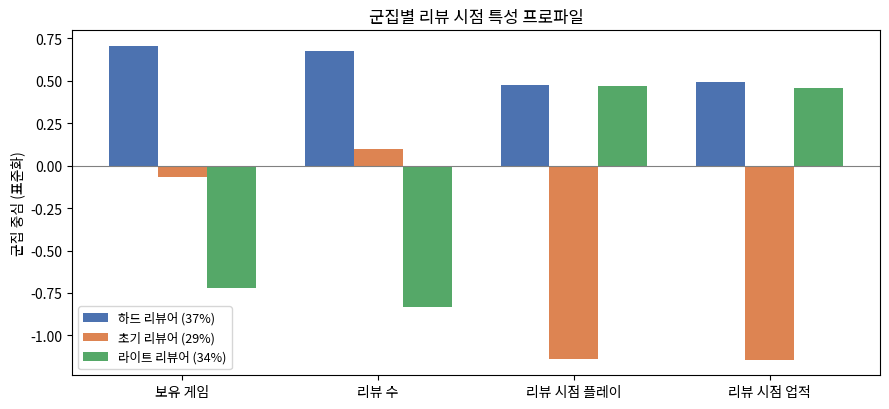

In [8]:
# 군집 중심 막대그래프
LABELS = {'games_owned': '보유 게임', 'num_reviews': '리뷰 수',
          'playtime_at_review_min': '리뷰 시점 플레이', 'n_ach_at_review': '리뷰 시점 업적'}
x = np.arange(len(FEATURES))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, name in enumerate(PERSONAS):
    cluster_id = [c for c, n in cluster_to_name.items() if n == name][0]
    share = profile.loc[name, '비율'] * 100
    ax.bar(x + (i - 1) * width, centers.loc[cluster_id], width=width, color=COLOR[name], label=f'{name} ({share:.0f}%)')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([LABELS[f] for f in FEATURES])
ax.set_ylabel('군집 중심 (표준화)')
ax.set_title('군집별 리뷰 시점 특성 프로파일')
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig('out/06_군집_프로파일.png', dpi=120)
plt.show()

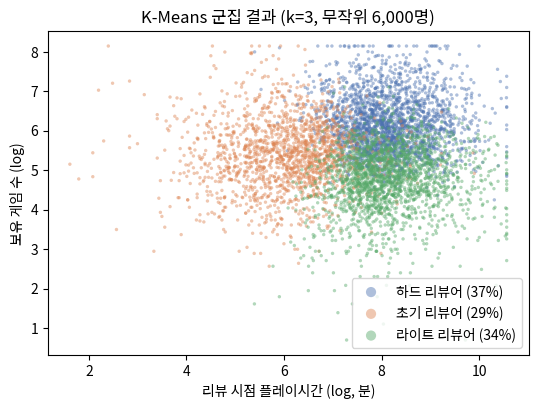

In [9]:
# 산점도: 두 축(플레이시간, 보유 게임)만 골라 무작위 6,000명
rng = np.random.RandomState(RANDOM_STATE)
pick = rng.choice(len(df), 6000, replace=False)
sub = df.iloc[pick]

fig, ax = plt.subplots(figsize=(6.2, 4.2))
for name in PERSONAS:
    part = sub[sub['페르소나'] == name]
    share = (df['페르소나'] == name).mean() * 100
    ax.scatter(np.log(part['playtime_at_review_min']), np.log(part['games_owned']),
               s=6, alpha=0.45, color=COLOR[name], edgecolors='none', label=f'{name} ({share:.0f}%)')
ax.set_xlabel('리뷰 시점 플레이시간 (log, 분)')
ax.set_ylabel('보유 게임 수 (log)')
ax.set_title('K-Means 군집 결과 (k=3, 무작위 6,000명)')
ax.legend(markerscale=3, loc='lower right')
fig.savefig('out/06_군집_산점도.png', dpi=150, bbox_inches='tight')
plt.show()

### 보조 지표 — 균형지수

실루엣 평균만으로는 "한 군집이 너무 크거나 작은" 결과를 걸러내지 못한다. 군집 크기와 군집별 실루엣 면적의 균형을 같이 본다.
(전체 70,915건에 silhouette_samples를 돌리므로 k마다 약 1분 걸린다.)

- 두께비 = 가장 큰 군집 크기 ÷ 가장 작은 군집 크기 (1에 가까울수록 균형)
- 최소상대면적 = 가장 작은 군집의 실루엣 면적 ÷ (전체 면적 ÷ k)
- 균형지수 = 실루엣 평균 × 최소상대면적 ÷ 두께비

In [10]:
rows = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(Z)
    s = silhouette_samples(Z, labels)             # 사람마다의 실루엣 값
    sizes = np.bincount(labels)                    # 군집별 인원
    areas = []
    for c in range(k):
        areas.append(s[labels == c].sum())         # 군집별 실루엣 합(면적)
    areas = np.array(areas)

    score = s.mean()
    thickness = sizes.max() / sizes.min()
    min_rel_area = areas.min() / (s.sum() / k)
    balance = score * min_rel_area / thickness
    rows.append({'k': k, '스코어': score, '전체면적': s.sum(), '두께비': thickness,
                 '최소상대면적': min_rel_area, '균형지수': balance})
    if k == K:
        s_k3 = s
        labels_k3 = labels
balance_table = pd.DataFrame(rows).set_index('k')
print(balance_table.round(3))

      스코어       전체면적    두께비  최소상대면적   균형지수
k                                         
2   0.279  19789.913  1.463   0.684  0.130
3   0.259  18349.433  1.264   0.826  0.169
4   0.230  16345.422  1.753   0.724  0.095
5   0.214  15188.546  2.007   0.642  0.068
6   0.215  15225.978  1.913   0.685  0.077
7   0.203  14396.838  2.126   0.645  0.062
8   0.202  14357.201  1.724   0.681  0.080
9   0.193  13675.849  2.156   0.650  0.058
10  0.191  13518.799  2.150   0.671  0.059


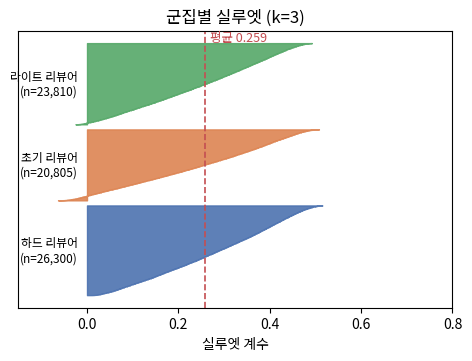

In [11]:
# k=3 실루엣 그림: 군집마다 실루엣 값을 정렬해서 쌓는다
fig, ax = plt.subplots(figsize=(5.6, 3.6))
y0 = 0
for c in range(K):
    values = np.sort(s_k3[labels_k3 == c])
    n = len(values)
    name = cluster_to_name[c]
    ax.fill_betweenx(np.arange(y0, y0 + n), 0, values, color=COLOR[name], alpha=0.9)
    ax.text(-0.02, y0 + n / 2, f'{name}\n(n={n:,})', ha='right', va='center', fontsize=8.5)
    y0 = y0 + n + 1500
ax.axvline(s_k3.mean(), color='#C44E52', ls='--', lw=1.2)
ax.text(s_k3.mean() + 0.01, y0 - 1000, f'평균 {s_k3.mean():.3f}', color='#C44E52', fontsize=9)
ax.set_xlabel('실루엣 계수')
ax.set_yticks([])
ax.set_xlim(-0.15, 0.8)
ax.set_title(f'군집별 실루엣 (k={K})')
fig.savefig('out/06_실루엣_k3.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 페르소나 프로파일 표 (PPT 6-3)

리뷰 이후 플레이시간 = 총 플레이 − 리뷰 시점 플레이 (둘 다 상한값 대체 후 값). 이탈 비율 = 리뷰 이후 플레이가 10시간 미만인 비율.

In [12]:
df['리뷰이후h'] = (df['playtime_forever_min'] - df['playtime_at_review_min']) / 60
df['이탈'] = df['리뷰이후h'] < 10

table = df.groupby('페르소나').agg(
    인원=('steamid', 'size'),
    보유게임=('games_owned', 'median'),
    리뷰수=('num_reviews', 'median'),
    리뷰시점_플레이분=('playtime_at_review_min', 'median'),
    업적=('n_ach_at_review', 'median'),
    리뷰이후_플레이h=('리뷰이후h', 'median'),
    이탈비율=('이탈', 'mean'),
    긍정률=('voted_up', 'mean'),
)
table = table.loc[PERSONAS]
table['리뷰시점_플레이h'] = table['리뷰시점_플레이분'] / 60

# 전체 행 추가
table.loc['전체'] = [len(df), df['games_owned'].median(), df['num_reviews'].median(),
                   df['playtime_at_review_min'].median(), df['n_ach_at_review'].median(),
                   df['리뷰이후h'].median(), df['이탈'].mean(), df['voted_up'].mean(),
                   df['playtime_at_review_min'].median() / 60]
table['비율'] = table['인원'] / len(df)
print('페르소나 프로파일 (PPT 6-3)')
print(table.round(3))

# 리뷰 시점 진행 단계 구성 (%)
df['구간'] = pd.cut(df['stage_at_review'], [-1, 1, 2, 4, 9, 10], labels=['0~1 초반', '2 이탈구간', '3~4', '5~9', '10 완주'])
stage_share = pd.crosstab(df['페르소나'], df['구간'], normalize='index') * 100
print()
print('군집별 리뷰 시점 단계 구성 (%)')
print(stage_share.loc[PERSONAS].round(1))

페르소나 프로파일 (PPT 6-3)
              인원   보유게임   리뷰수  리뷰시점_플레이분    업적  리뷰이후_플레이h   이탈비율    긍정률  \
페르소나                                                                      
하드 리뷰어   26300.0  431.0  29.0     3337.0  17.0     20.300  0.407  0.574   
초기 리뷰어   20805.0  220.0  16.0      491.0   3.0      9.683  0.503  0.478   
라이트 리뷰어  23810.0  124.0   5.0     3236.0  16.0     28.858  0.341  0.650   
전체       70915.0  237.0  14.0     2286.0  10.0     19.717  0.413  0.572   

         리뷰시점_플레이h     비율  
페르소나                       
하드 리뷰어      55.617  0.371  
초기 리뷰어       8.183  0.293  
라이트 리뷰어     53.933  0.336  
전체          38.100  1.000  

군집별 리뷰 시점 단계 구성 (%)
구간       0~1 초반  2 이탈구간   3~4   5~9  10 완주
페르소나                                      
하드 리뷰어      1.9    33.6  20.0  17.7   26.9
초기 리뷰어     27.9    67.0   4.4   0.6    0.1
라이트 리뷰어     2.0    33.7  19.7  19.2   25.5


## 6. 군집별 텍스트 분류 정확도 (PPT 19p "유저 유형별 AUC")

추천확률(05b)이 세 유형 모두에서 비슷하게 잘 맞는지 본다. 그래야 07에서 유형끼리 같은 잣대로 비교할 수 있다.
정확도만 보면 잘못 읽을 수 있다 — 긍정률 90%인 군집은 전부 "추천"이라 찍어도 90%다. 그래서 AUC와 다수 클래스 기준선을 같이 본다.

In [13]:
score = pd.read_csv('dataSets/추천확률.csv')
df = df.merge(score, on='steamid', how='left')
df['y'] = df['voted_up'].astype(int)
df['맞춤'] = (df['추천확률'] >= 0.5) == df['y']

rows = []
for name in PERSONAS + ['전체']:
    if name == '전체':
        g = df
    else:
        g = df[df['페르소나'] == name]
    p = g['y'].mean()
    rows.append({
        '페르소나': name,
        'n': len(g),
        '긍정률': p,
        '기준선': max(p, 1 - p),            # 다수 클래스만 찍었을 때의 정확도
        '정확도': g['맞춤'].mean(),
        'AUC': roc_auc_score(g['y'], g['추천확률']),
        '리뷰길이_중앙': g['len'].median(),
    })
acc = pd.DataFrame(rows).set_index('페르소나')
acc['정확도-기준선'] = acc['정확도'] - acc['기준선']
print(acc.round(3))

             n    긍정률    기준선    정확도    AUC  리뷰길이_중앙  정확도-기준선
페르소나                                                        
하드 리뷰어   26300  0.574  0.574  0.878  0.948    159.0    0.304
초기 리뷰어   20805  0.478  0.522  0.877  0.949     69.0    0.355
라이트 리뷰어  23810  0.650  0.650  0.905  0.963     82.0    0.255
전체       70915  0.572  0.572  0.887  0.954     98.0    0.315


## 7. 정리

- 리뷰 시점 특성 4개로 세 유형이 갈린다: **초기 리뷰어** 29%(플레이 8h·업적 3), **하드 리뷰어** 37%(보유 게임 431·리뷰 29편·56h), **라이트 리뷰어** 34%(보유 게임 124·리뷰 5편·54h).
- 세 유형의 긍정률은 48% / 57% / 65%, 리뷰 이후 플레이 중앙값은 9.7h / 20.3h / 28.9h — 초기 리뷰어가 가장 부정적이고 가장 빨리 떠난다.
- 텍스트 분류기는 세 유형 모두 AUC 0.95 안팎 — 유형 비교에 같은 잣대를 쓸 수 있다.